# ISI / KS CUSUM changepoint method: worked example

One neuron gets a step in its mean input current at `changepoint`, with white noise added.
1. Simulate `N_ref` repeats of the same condition (independent noise each time).
2. Pool their ISIs into two **reference distributions**: ISIs ending before the changepoint, and ISIs starting after it.
3. For one trial, slide a window of `n_isi` consecutive ISIs along the spike train. For each window compute
   `d = KS(window, pre_ref) - KS(window, post_ref)`. A value > 0 means the window looks more like the post-changepoint references.
4. The changepoint is the minimum of the CUSUM curve `s = cumsum(d)`: the split where windows before it are as pre-like (`d < 0`)
   and windows after it as post-like (`d > 0`) as possible. This is effectively where `d` crosses zero, but robust to noisy multiple crossings.
   The score is `mean(d after) - mean(d before)`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats

from aqua.batchAQUA_general import batchAQUA
from aqua.stimulus import step_current
from CP_functions import spike_isis, reference_isis, ks_window_cp, fit_isi_distribution, llr_cp
from CPA_with_AQUA import RS

import seaborn as sns
sns.set_style('ticks')   # CPA_with_AQUA sets a gridded theme on import

In [2]:
# --- parameters ---
T = 5000            # ms
dt = 0.1            # ms
changepoint = 2500  # ms
I_0 = 60            # pA, baseline current
H = 20              # pA, step height
var = 1            # noise variance
noise_rate = 50     # Hz, noise sample rate
f = 250               # autapse strength
e, tau = 0.2, 2.0   # autapse decay (/ms) and delay (ms)

n_isi = 5           # ISIs per window
t_discard = 200     # ms, ignore the initial transient
N_ref = 50          # repeats used to build the reference distributions

np.random.seed(1)

In [3]:
# --- simulate N_ref repeats of the same neuron, independent noise each ---
N_iter = int(T/dt)
noise_steps = int(1/noise_rate * (1000/dt))
num_unique = N_iter // noise_steps

params = pd.DataFrame([{**RS, 'e': e, 'tau': tau, 'f': f} for _ in range(N_ref)])
step = step_current(N_iter, dt, y_0 = I_0, delay = changepoint, I_h = I_0 + H)
I_inj = np.array([step + np.repeat(np.random.normal(0, np.sqrt(var), num_unique), noise_steps)
                  for _ in range(N_ref)])

batch = batchAQUA(params)
batch.Initialise(np.full((N_ref, 3), [-60., 0., 0.]), np.zeros(N_ref))
X, t, spikes = batch.update_batch(dt, N_iter, I_inj)   # SAVE_ALL = True so V(t) can be plotted

  0%|          | 0/49999 [00:00<?, ?it/s]

100%|██████████| 49999/49999 [00:06<00:00, 7874.35it/s]


In [4]:
# --- reference distributions (pooled over all repeats) ---
isis = [spike_isis(s, t_discard) for s in spikes]
pre_ref, post_ref = reference_isis(isis, changepoint)
print(f"pre reference: {len(pre_ref)} ISIs, median {np.median(pre_ref):.1f} ms")
print(f"post reference: {len(post_ref)} ISIs, median {np.median(post_ref):.1f} ms")

# --- detect the changepoint on one example trial ---
trial = 0
isi, t_isi = isis[trial]
CP, score, t_win, d, s = ks_window_cp(isi, t_isi, pre_ref, post_ref, n_isi, return_trace = True)
print(f"estimated CP = {CP:.0f} ms (true {changepoint} ms), score = {score:.2f}")

pre reference: 845 ISIs, median 110.7 ms
post reference: 1857 ISIs, median 30.4 ms
estimated CP = 2527 ms (true 2500 ms), score = 0.49


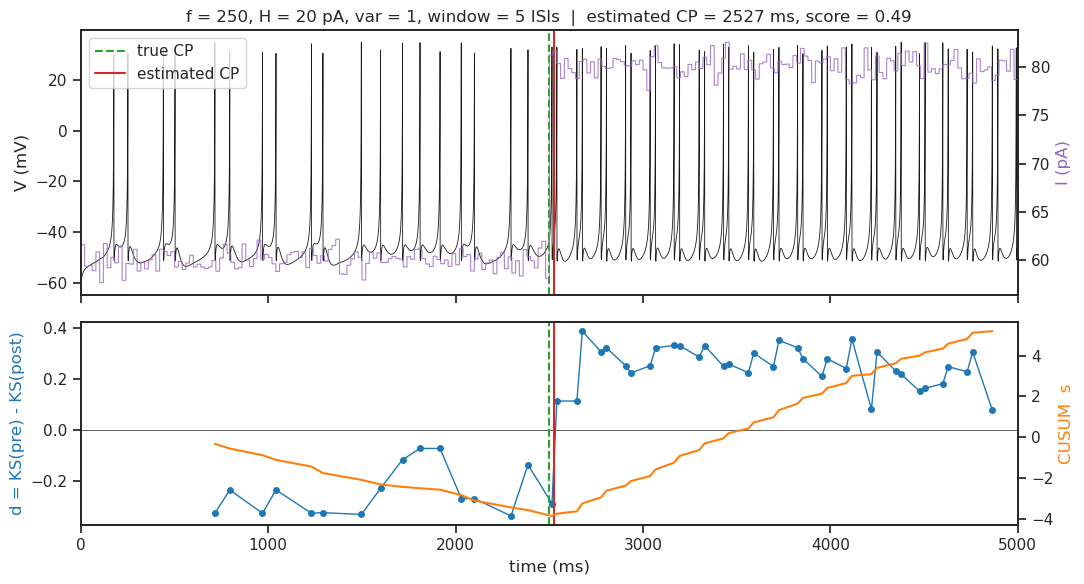

In [5]:
fig, (ax_v, ax_d) = plt.subplots(2, 1, figsize = (11, 6), sharex = True,
                                 gridspec_kw = {'height_ratios': [1.3, 1]})

# top: membrane potential + injected current
ax_v.plot(t, X[trial, 0], color = 'k', lw = 0.6)
ax_v.set_ylabel('V (mV)')
ax_i = ax_v.twinx()
ax_i.plot(t, I_inj[trial], color = 'tab:purple', lw = 0.8, alpha = 0.8)
ax_i.set_ylabel('I (pA)', color = 'tab:purple')
ax_v.set_title(f'f = {f}, H = {H} pA, var = {var}, window = {n_isi} ISIs  |  '
               f'estimated CP = {CP:.0f} ms, score = {score:.2f}')

# bottom: KS difference per window + CUSUM curve
ax_d.axhline(0, color = 'k', lw = 0.5)
ax_d.plot(t_win, d, 'o-', color = 'tab:blue', ms = 4, lw = 1)
ax_d.set_ylabel('d = KS(pre) - KS(post)', color = 'tab:blue')
ax_s = ax_d.twinx()
ax_s.plot(t_win, s, color = 'tab:orange', lw = 1.5)
ax_s.set_ylabel('CUSUM  s', color = 'tab:orange')
ax_d.set_xlabel('time (ms)')

for ax in (ax_v, ax_d):
    ax.axvline(changepoint, color = 'tab:green', ls = '--', lw = 1.5, label = 'true CP')
    ax.axvline(CP, color = 'tab:red', lw = 1.5, label = 'estimated CP')
ax_v.legend(loc = 'upper left')
ax_v.set_xlim(0, T)
fig.tight_layout()
plt.show()

## Log-likelihood-ratio (LLR) CUSUM

Same idea, but every single ISI is scored instead of windows:
1. Fit five candidates to the pre and post references separately: gamma, lognormal and inverse Gaussian (location fixed at 0), and 2- and 3-component Gaussian mixtures on log(ISI) (`gmm2`, `gmm3`) for multimodal, bursting ISI distributions. For each reference, keep the candidate with the lowest BIC.
2. For each ISI, `l = log p_post(isi) - log p_pre(isi)` (> 0: post-like), clipped to ±10 so a single extreme ISI cannot dominate.
3. The changepoint is the minimum of `s = cumsum(l)`, which is the maximum-likelihood single change. Score = `mean(l after) - mean(l before)`.

Resolution is one ISI and there is no window size, but the result depends on how well the fitted densities match the data.

In [6]:
dist_pre, name_pre, table_pre = fit_isi_distribution(pre_ref)
dist_post, name_post, table_post = fit_isi_distribution(post_ref)
print(f"pre:  chosen {name_pre}"); display(table_pre.drop(columns = 'dist'))
print(f"post: chosen {name_post}"); display(table_post.drop(columns = 'dist'))

pre:  chosen gmm3


,family,params,logL,BIC,KS
0,gmm3,"(0.4271, 4.2776, 0.1414, 0.1603, 4.7391, 0.208...",-4177.810061,8409.534815,0.034779
1,gmm2,"(0.5535, 4.3662, 0.2195, 0.4465, 5.2215, 0.1084)",-4223.927259,8481.551202,0.043695
2,invgauss,"(0.2298, 0.0, 556.4412)",-4546.417985,9106.314644,0.161252
3,lognorm,"(0.4612, 0.0, 115.3702)",-4557.255708,9127.990089,0.160911
4,gamma,"(5.0192, 0.0, 25.4773)",-4557.564885,9128.608443,0.153238


post: chosen gmm3


,family,params,logL,BIC,KS
0,gmm3,"(0.4988, 3.3637, 0.0214, 0.0202, 3.8844, 0.519...",-4792.004780,9644.223301,0.026057
1,gmm2,"(0.5094, 3.3648, 0.0309, 0.4906, 4.6258, 0.0493)",-5286.173117,10609.979823,0.062157
2,invgauss,"(0.4553, 0.0, 142.4984)",-9125.965579,18266.984593,0.316361
3,lognorm,"(0.6317, 0.0, 53.6988)",-9179.189566,18373.432568,0.317146
4,gamma,"(2.7992, 0.0, 23.178)",-9186.076773,18387.206980,0.321370


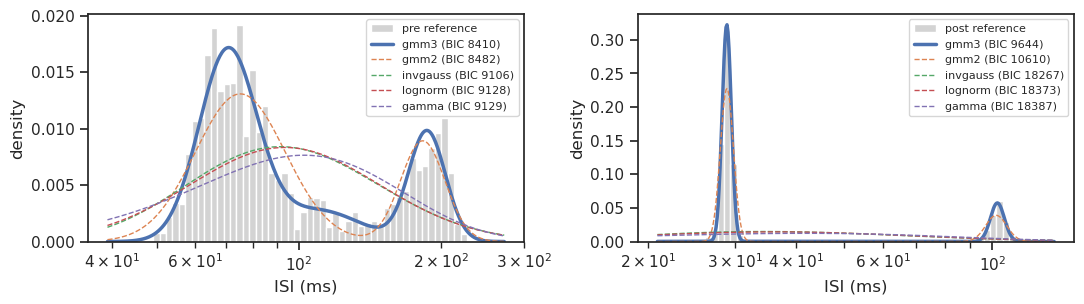

In [7]:
# reference ISIs with all fitted densities; the chosen one is drawn bold
fig, axes = plt.subplots(1, 2, figsize = (11, 3.2))
for ax, ref, table, chosen, label in [(axes[0], pre_ref, table_pre, name_pre, 'pre'),
                                      (axes[1], post_ref, table_post, name_post, 'post')]:
    log_axis = chosen.startswith('gmm')         # bursting: log axis resolves the narrow intra-burst peak
    if log_axis:
        x = np.logspace(np.log10(ref.min() * 0.8), np.log10(ref.max() * 1.2), 400)
        bins = np.logspace(np.log10(ref.min()), np.log10(ref.max()), 50)
        ax.set_xscale('log')
    else:
        x = np.linspace(ref.min() * 0.8, ref.max() * 1.2, 400)
        bins = 40
    ax.hist(ref, bins = bins, density = True, color = 'lightgrey', label = f'{label} reference')
    for _, row in table.iterrows():
        if row['dist'] is None:
            continue
        bold = row['family'] == chosen
        ax.plot(x, row['dist'].pdf(x), lw = 2.5 if bold else 1, ls = '-' if bold else '--',
                label = f"{row['family']} (BIC {row['BIC']:.0f})")
    ax.set_xlabel('ISI (ms)'); ax.set_ylabel('density'); ax.legend(fontsize = 8)
fig.tight_layout()
plt.show()

In [8]:
# --- LLR detection on the same trial ---
CP_llr, score_llr, t_l, l, s_l = llr_cp(isi, t_isi, dist_pre, dist_post, return_trace = True)
print(f"KS : estimated CP = {CP:.0f} ms, score = {score:.2f}")
print(f"LLR: estimated CP = {CP_llr:.0f} ms, score = {score_llr:.2f}   (true {changepoint} ms)")

KS : estimated CP = 2527 ms, score = 0.49
LLR: estimated CP = 2514 ms, score = 10.65   (true 2500 ms)


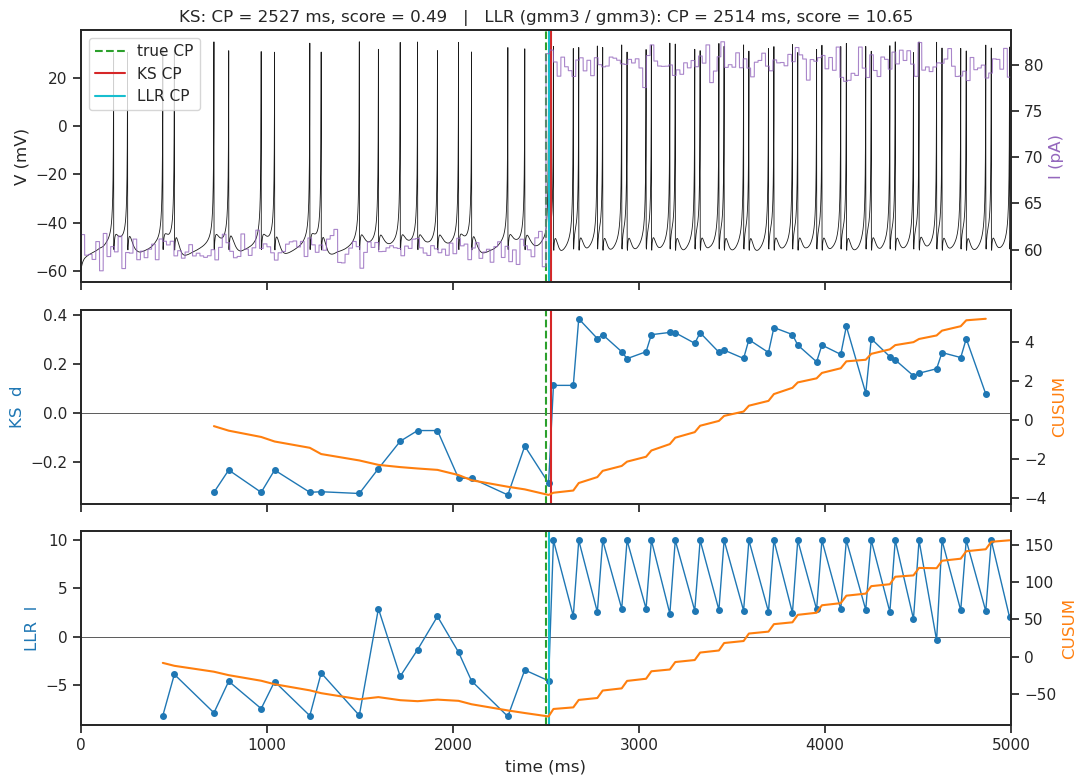

In [9]:
fig, (ax_v, ax_d, ax_l) = plt.subplots(3, 1, figsize = (11, 8), sharex = True,
                                       gridspec_kw = {'height_ratios': [1.3, 1, 1]})

# top: membrane potential + injected current
ax_v.plot(t, X[trial, 0], color = 'k', lw = 0.6)
ax_v.set_ylabel('V (mV)')
ax_i = ax_v.twinx()
ax_i.plot(t, I_inj[trial], color = 'tab:purple', lw = 0.8, alpha = 0.8)
ax_i.set_ylabel('I (pA)', color = 'tab:purple')
ax_v.set_title(f'KS: CP = {CP:.0f} ms, score = {score:.2f}   |   '
               f'LLR ({name_pre} / {name_post}): CP = {CP_llr:.0f} ms, score = {score_llr:.2f}')

# middle: KS difference per window + CUSUM
ax_d.axhline(0, color = 'k', lw = 0.5)
ax_d.plot(t_win, d, 'o-', color = 'tab:blue', ms = 4, lw = 1)
ax_d.set_ylabel('KS  d', color = 'tab:blue')
ax_ds = ax_d.twinx()
ax_ds.plot(t_win, s, color = 'tab:orange', lw = 1.5)
ax_ds.set_ylabel('CUSUM', color = 'tab:orange')

# bottom: log-likelihood ratio per ISI + CUSUM
ax_l.axhline(0, color = 'k', lw = 0.5)
ax_l.plot(t_l, l, 'o-', color = 'tab:blue', ms = 4, lw = 1)
ax_l.set_ylabel('LLR  l', color = 'tab:blue')
ax_ls = ax_l.twinx()
ax_ls.plot(t_l, s_l, color = 'tab:orange', lw = 1.5)
ax_ls.set_ylabel('CUSUM', color = 'tab:orange')
ax_l.set_xlabel('time (ms)')

for ax, cp in [(ax_v, None), (ax_d, CP), (ax_l, CP_llr)]:
    ax.axvline(changepoint, color = 'tab:green', ls = '--', lw = 1.5, label = 'true CP')
    if cp is None:
        ax.axvline(CP, color = 'tab:red', lw = 1.5, label = 'KS CP')
        ax.axvline(CP_llr, color = 'tab:cyan', lw = 1.5, label = 'LLR CP')
    else:
        ax.axvline(cp, color = 'tab:red' if ax is ax_d else 'tab:cyan', lw = 1.5)
ax_v.legend(loc = 'upper left')
ax_v.set_xlim(0, T)
fig.tight_layout()
plt.show()

## ISI-pair (Markov) LLR CUSUM

Bursting makes successive ISIs dependent (short → short → long ...). The 1D model ignores ISI order, so this version models **pairs** of consecutive ISIs:
1. Pool consecutive pairs `(ISI_{n-1}, ISI_n)` from all repeats. A pair is pre if both ISIs lie before the changepoint, post if both lie after; straddling pairs are dropped.
2. Fit 2D Gaussian mixtures (K = 1, 2, 3, full covariances) to `(log ISI_{n-1}, log ISI_n)` and keep the lowest BIC, separately for pre and post.
3. Score each ISI by the conditional log-likelihood ratio `l = log p_post(ISI_n | ISI_{n-1}) - log p_pre(ISI_n | ISI_{n-1})` (clipped to ±10). The changepoint is again `argmin cumsum(l)`. The first ISI has no predecessor and is not scored.

In [10]:
from CP_functions import reference_pairs, fit_isi_pair_distribution, llr_pair_cp

pre_pairs, post_pairs = reference_pairs(isis, changepoint)
pdist_pre, pname_pre, ptable_pre = fit_isi_pair_distribution(pre_pairs)
pdist_post, pname_post, ptable_post = fit_isi_pair_distribution(post_pairs)
print(f"pre:  {len(pre_pairs)} pairs, chosen {pname_pre}"); display(ptable_pre.drop(columns = 'dist'))
print(f"post: {len(post_pairs)} pairs, chosen {pname_post}"); display(ptable_post.drop(columns = 'dist'))

pre:  795 pairs, chosen pair_gmm3


,family,logL,BIC
0,pair_gmm3,440.949837,-768.367858
1,pair_gmm2,266.167104,-458.872445
2,pair_gmm1,-261.611900,556.615511


post: 1807 pairs, chosen pair_gmm3


,family,logL,BIC
0,pair_gmm3,6694.004672,-13260.519148
1,pair_gmm2,6146.158714,-12209.823773
2,pair_gmm1,1683.249827,-3329.002538


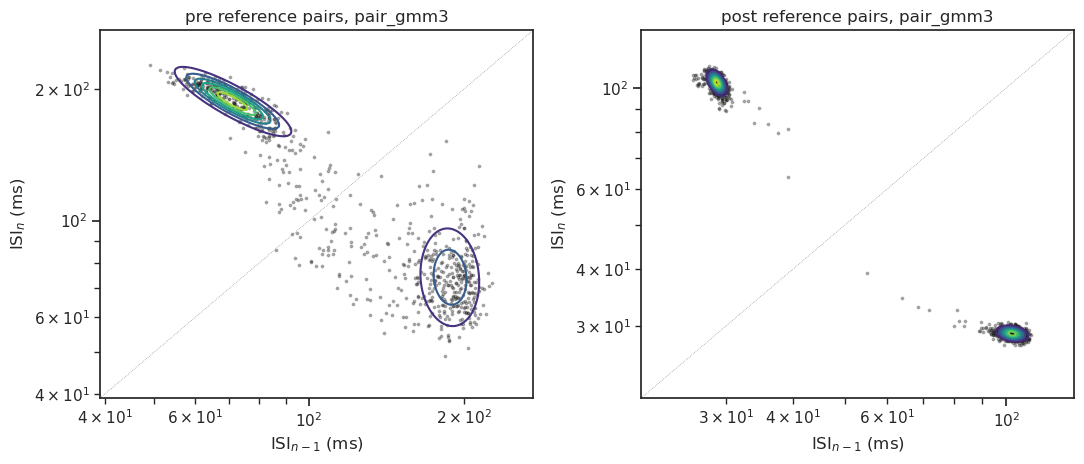

In [11]:
# return maps: each point is one pair of consecutive ISIs; contours are the chosen 2D mixture
fig, axes = plt.subplots(1, 2, figsize = (11, 4.8))
for ax, pairs, dist, name, label in [(axes[0], pre_pairs, pdist_pre, pname_pre, 'pre'),
                                     (axes[1], post_pairs, pdist_post, pname_post, 'post')]:
    ax.scatter(pairs[:, 0], pairs[:, 1], s = 3, alpha = 0.3, color = 'k')
    lo, hi = np.log(pairs.min() * 0.8), np.log(pairs.max() * 1.2)
    g = np.linspace(lo, hi, 200)
    A, B = np.meshgrid(g, g)
    Z = np.exp(dist.gmm.score_samples(np.column_stack([A.ravel(), B.ravel()]))).reshape(A.shape)
    ax.contour(np.exp(A), np.exp(B), Z, levels = 8, cmap = 'viridis')
    ax.plot([np.exp(lo), np.exp(hi)], [np.exp(lo), np.exp(hi)], color = 'grey', lw = 0.5, ls = ':')
    ax.set_xscale('log'); ax.set_yscale('log')
    ax.set_xlabel('ISI$_{n-1}$ (ms)'); ax.set_ylabel('ISI$_n$ (ms)')
    ax.set_title(f'{label} reference pairs, {name}')
fig.tight_layout()
plt.show()

In [12]:
# --- pair-LLR detection on the same trial ---
CP_pair, score_pair, t_p, l_p, s_p = llr_pair_cp(isi, t_isi, pdist_pre, pdist_post, return_trace = True)
print(f"KS      : CP = {CP:.0f} ms, score = {score:.2f}")
print(f"LLR     : CP = {CP_llr:.0f} ms, score = {score_llr:.2f}")
print(f"LLR pair: CP = {CP_pair:.0f} ms, score = {score_pair:.2f}   (true {changepoint} ms)")

KS      : CP = 2527 ms, score = 0.49
LLR     : CP = 2514 ms, score = 10.65
LLR pair: CP = 2514 ms, score = 19.99   (true 2500 ms)


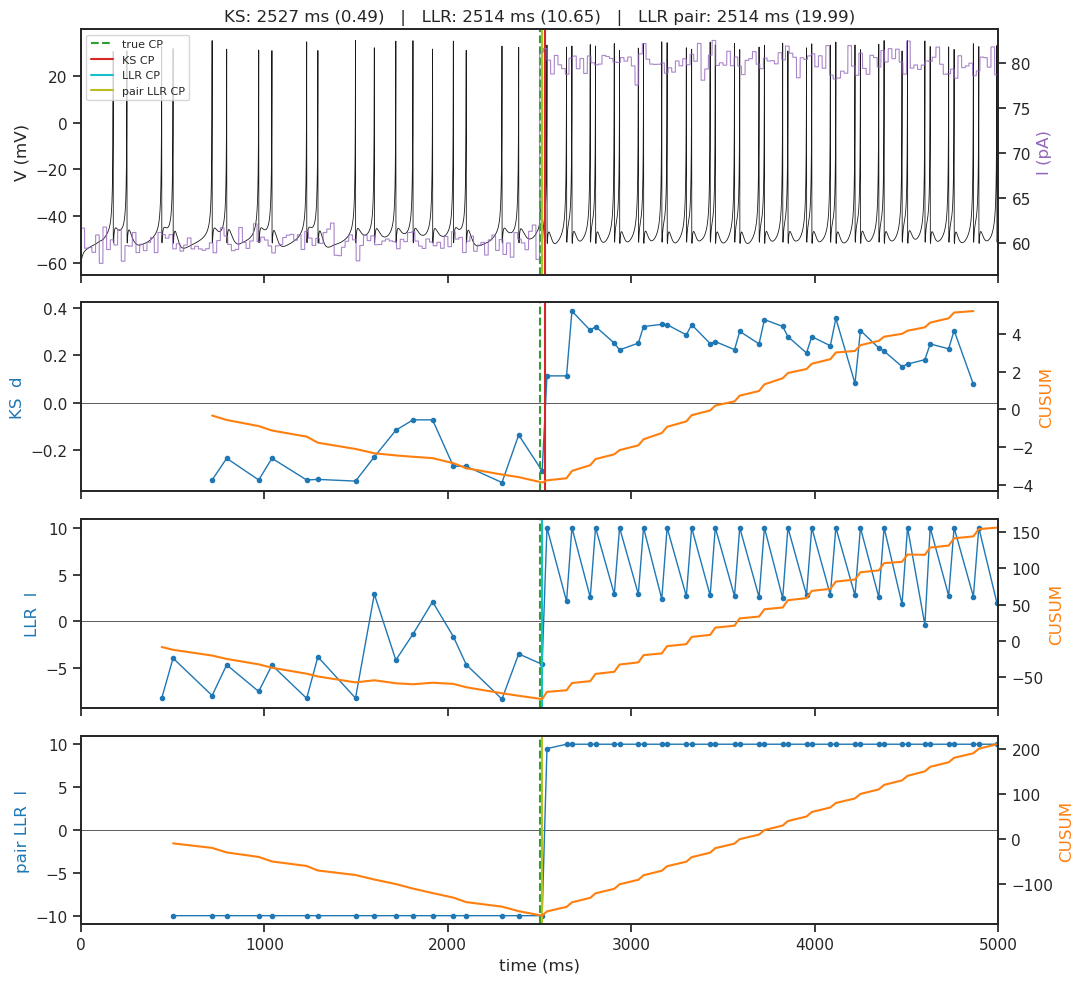

In [13]:
fig, axs = plt.subplots(4, 1, figsize = (11, 10), sharex = True,
                        gridspec_kw = {'height_ratios': [1.3, 1, 1, 1]})
ax_v = axs[0]
ax_v.plot(t, X[trial, 0], color = 'k', lw = 0.6)
ax_v.set_ylabel('V (mV)')
ax_i = ax_v.twinx()
ax_i.plot(t, I_inj[trial], color = 'tab:purple', lw = 0.8, alpha = 0.8)
ax_i.set_ylabel('I (pA)', color = 'tab:purple')
ax_v.set_title(f'KS: {CP:.0f} ms ({score:.2f})   |   LLR: {CP_llr:.0f} ms ({score_llr:.2f})   |   '
               f'LLR pair: {CP_pair:.0f} ms ({score_pair:.2f})')

rows = [(axs[1], t_win, d, s, 'KS  d', CP, 'tab:red', 'KS CP'),
        (axs[2], t_l, l, s_l, 'LLR  l', CP_llr, 'tab:cyan', 'LLR CP'),
        (axs[3], t_p, l_p, s_p, 'pair LLR  l', CP_pair, 'tab:olive', 'pair LLR CP')]
for ax, tt, val, cus, lab, cp, col, _ in rows:
    ax.axhline(0, color = 'k', lw = 0.5)
    ax.plot(tt, val, 'o-', color = 'tab:blue', ms = 3, lw = 1)
    ax.set_ylabel(lab, color = 'tab:blue')
    ax2 = ax.twinx()
    ax2.plot(tt, cus, color = 'tab:orange', lw = 1.5)
    ax2.set_ylabel('CUSUM', color = 'tab:orange')
    ax.axvline(changepoint, color = 'tab:green', ls = '--', lw = 1.5)
    ax.axvline(cp, color = col, lw = 1.5)

ax_v.axvline(changepoint, color = 'tab:green', ls = '--', lw = 1.5, label = 'true CP')
for *_, cp, col, cp_label in rows:
    ax_v.axvline(cp, color = col, lw = 1.5, label = cp_label)
ax_v.legend(loc = 'upper left', fontsize = 8)
axs[3].set_xlabel('time (ms)')
ax_v.set_xlim(0, T)
fig.tight_layout()
plt.show()